In [1]:
import pandas, numpy, scipy

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [3]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

In [4]:
input_file = '/Users/adrian/research/bmcbf/067_urmia/results/03_cell_lines/DESeq2_TPM_values.tsv'

# 1. read expression

In [5]:
expression = pandas.read_csv(input_file, sep='\t', index_col=0)
print(expression.shape)
expression

(39546, 24)


,Ind25NT1,Ind25NT2,Ind25NT3,Ind25T251,Ind25T252,Ind25T253,Ind25T501,Ind25T502,Ind25T503,Ind5NT1,...,Ind5T253,Ind5T501,Ind5T502,Ind5T503,NI1,NI2,NI3,P1C20A4,P2C20A4,P3C20A4
ENSG00000000003.15,7.970509,6.919597,1.381531,2.063145,2.307764,1.255518,0.990330,3.603627,3.503651,2.309373,...,3.048057,1.287731,2.438772,1.974410,0.859654,1.062616,1.840028,23.960389,30.228594,23.373350
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,20.447793,21.265525,8.896596,9.252670,11.103878,4.297124,9.198689,20.274685,20.419256,12.007703,...,23.470436,10.331776,13.434923,10.348828,11.313461,8.898594,12.895034,129.510836,126.882972,116.139091
ENSG00000000457.14,0.000000,0.324166,0.108314,0.170471,0.442764,0.000000,0.325638,0.357153,0.000000,0.000000,...,0.564511,0.317279,0.336218,0.432905,0.166953,0.000000,0.000000,4.657041,4.673203,5.667404
ENSG00000000460.17,3.979794,1.143713,0.614262,1.067896,6.670395,2.181708,0.624556,1.978326,1.147153,0.945842,...,3.015357,0.303372,3.306845,0.000000,0.386829,2.734151,0.882947,20.471935,21.009739,31.100158
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,0.000000,0.000000,0.000000,0.069990,0.000000,1.002814,0.000000,0.000000,0.000000,0.000000,...,0.620413,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.700925,3.218583,2.526474
ENSG00000291300.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.038188,0.219504,0.134650


In [6]:
for element in expression.columns:
    print(element)

Ind25NT1
Ind25NT2
Ind25NT3
Ind25T251
Ind25T252
Ind25T253
Ind25T501
Ind25T502
Ind25T503
Ind5NT1
Ind5NT2
Ind5NT3
Ind5T251
Ind5T252
Ind5T253
Ind5T501
Ind5T502
Ind5T503
NI1
NI2
NI3
P1C20A4
P2C20A4
P3C20A4


# 3. filter and transform

In [7]:
substantial_expression = expression[expression.max(axis=1) >= 2]
high_expression = expression[expression.max(axis=1) >= 100]

print(substantial_expression.shape)
print(high_expression.shape)

(14373, 24)
(2174, 24)


In [8]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize high expression

In [9]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_high_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.86775615 0.02813446]


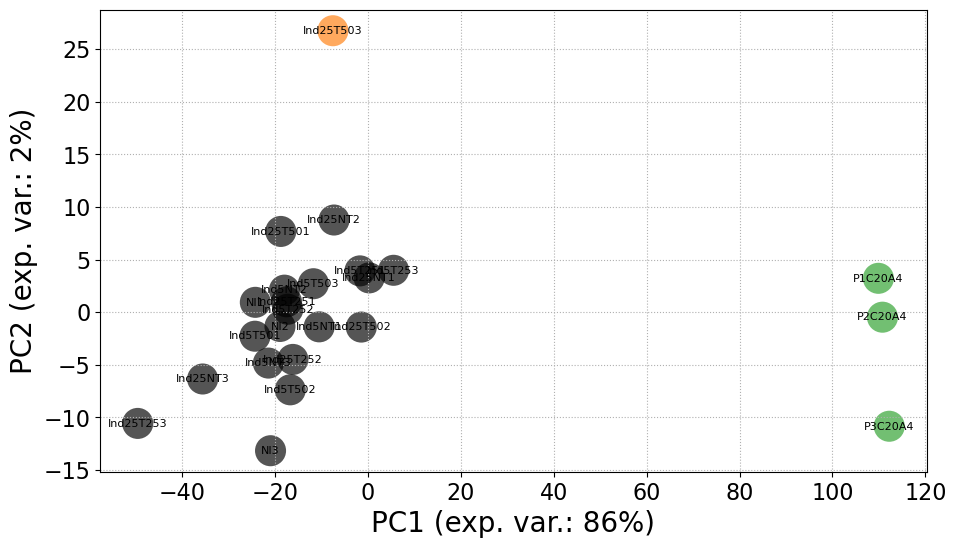

In [10]:
for i in range(len(new)):

    name = pca_high_expression.index[i]

    # colors
    if 'C20A4' in name:
        the_color = 'tab:green'
    elif 'Ind25T503' in name:
        the_color = 'tab:orange'
    else:
        the_color = 'black'
    
        
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=500, c=the_color, marker='o', alpha=2/3, edgecolors='none')
    epsilon = 0
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()
#matplotlib.pyplot.savefig('pca.svg')

In [11]:
# exclude C20A4 bc they are very different, and Ind25T503 bc is an outlier
print(pca_high_expression.shape)
pca_high_expression = pca_high_expression.drop(index=["Ind25T503", "P1C20A4", 'P2C20A4', 'P3C20A4'])
print(pca_high_expression.shape)

(24, 2174)
(20, 2174)


[0.43406853 0.07700745]


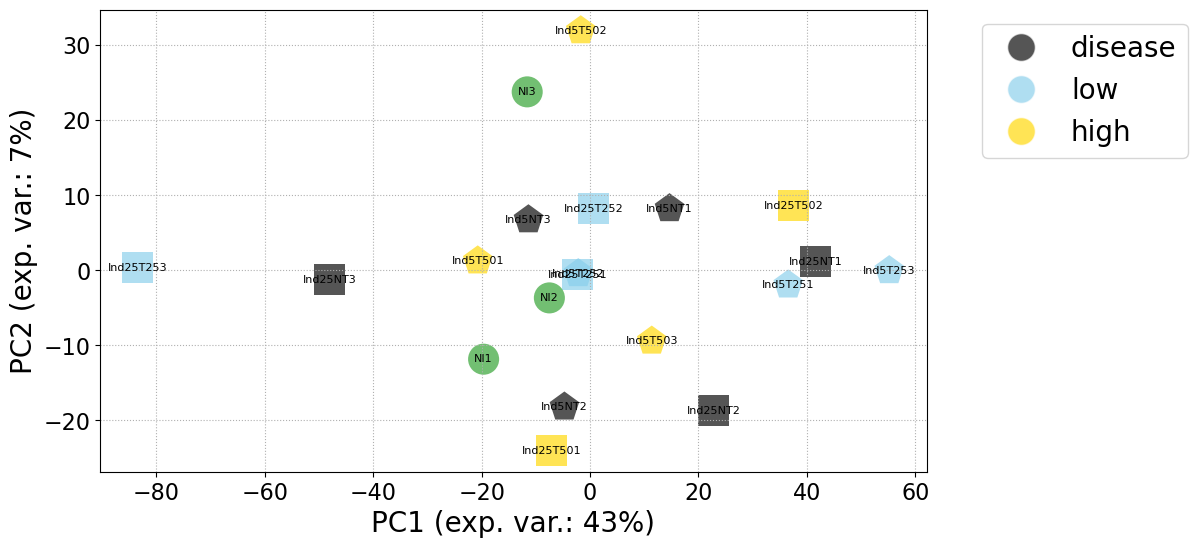

In [12]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_high_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

for i in range(len(new)):

    name = pca_high_expression.index[i]

    # colors
    if 'NI' in name:
        the_color = 'tab:green'
    elif 'NT' in name:
        the_color = 'black'
    elif 'T25' in name:
        the_color = 'skyblue'
    elif 'T50' in name:
        the_color = 'gold'
    else:
        print('error')

    # marker
    if 'Ind25' in name:
        the_marker = 's'
    elif 'Ind5' in name:
        the_marker = 'p'
    else:
        the_marker = 'o'

    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=500, c=the_color, marker=the_marker, alpha=2/3, edgecolors='none')
    epsilon = 0
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')

legend_elements = [
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='black', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='skyblue', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='gold', markeredgecolor='white', markersize=20, alpha=2/3)
]

matplotlib.pyplot.legend(legend_elements, ['disease', 'low', 'high'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()


In [13]:
# 5. distributions

In [14]:
log2_tpm_PO = numpy.log2(expression + 1)
log2_tpm_PO.head()

,Ind25NT1,Ind25NT2,Ind25NT3,Ind25T251,Ind25T252,Ind25T253,Ind25T501,Ind25T502,Ind25T503,Ind5NT1,...,Ind5T253,Ind5T501,Ind5T502,Ind5T503,NI1,NI2,NI3,P1C20A4,P2C20A4,P3C20A4
ENSG00000000003.15,3.165190,2.985427,1.251890,1.615014,1.725856,1.173459,0.993008,2.202771,2.171095,1.726558,...,2.017230,1.193918,1.781893,1.572604,0.895034,1.044475,1.505905,4.641568,4.964796,4.607233
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,4.422757,4.476740,3.306932,3.357928,3.597397,2.405209,3.350312,4.411066,4.420836,3.701294,...,4.612968,3.502302,3.851492,3.504471,3.622164,3.307224,3.796498,7.028026,6.998680,6.872079
ENSG00000000457.14,0.000000,0.405085,0.148367,0.227089,0.528835,0.000000,0.406687,0.440584,0.000000,0.000000,...,0.645711,0.397561,0.418156,0.518943,0.222747,0.000000,0.000000,2.500048,2.504163,2.737125
ENSG00000000460.17,2.316086,1.100112,0.690875,1.048164,2.939301,1.669802,0.700045,1.574502,1.102425,0.960394,...,2.005528,0.382249,2.106631,0.000000,0.471789,1.900780,0.912993,4.424380,4.460070,5.004509


186
18.55079303827768


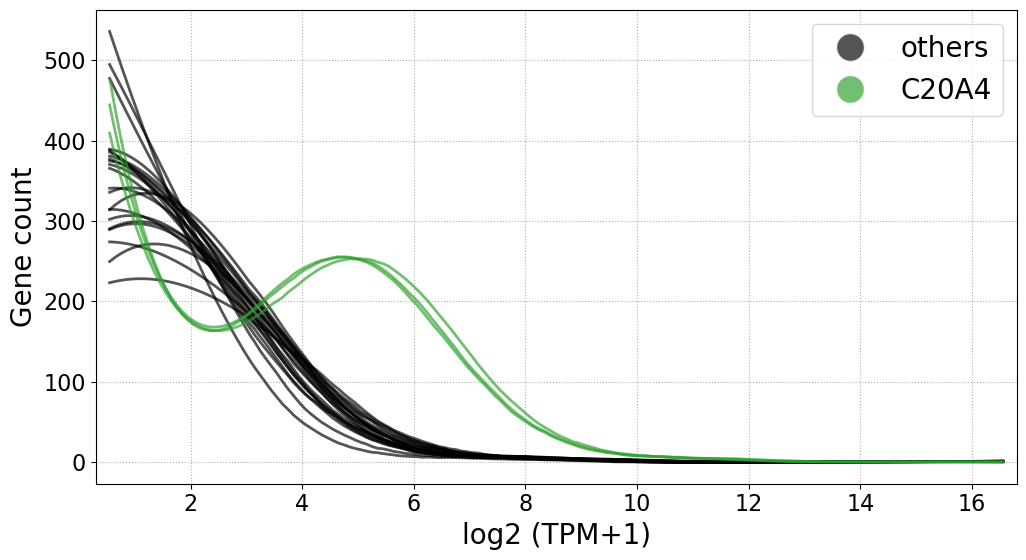

In [17]:
found_max = 18.6
number_of_bins = int(found_max*10)
print(number_of_bins)

absolute_max = 0
working_samples = log2_tpm_PO.columns.to_list()

most_likely_expressions = []
all_hats = []
for i in range(len(working_samples)):

    name = working_samples[i]

    # colors
    if 'C20A4' in name:
        the_color = 'tab:green'
    
    else:
        the_color = 'black'
    
    log2TPM = log2_tpm_PO.loc[:, name]
    if max(log2TPM) > absolute_max:
        absolute_max = max(log2TPM)
                
    hist, bin_edges = numpy.histogram(log2TPM, bins=number_of_bins, range=(0, found_max))
    half_bin = (bin_edges[1] - bin_edges[0])/2
    x = bin_edges + half_bin
    x = x[:-1]
  
    plotting_x = x[5:-20]
    plotting_hist = hist[5:-20]
    #print(plotting_x)
    
    #matplotlib.pyplot.plot(plotting_x, plotting_hist, 'o', alpha=1/5, mec='none', color=the_color)
    yhat = scipy.signal.savgol_filter(plotting_hist, 51, 3)

    matplotlib.pyplot.plot(plotting_x, yhat, '-', lw=2, alpha=2/3, color=the_color)
    
    
matplotlib.pyplot.xlim([numpy.min(plotting_x)-0.25, numpy.max(plotting_x)+0.25])
#matplotlib.pyplot.ylim([0, 400])

legend_elements = [
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='black', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='tab:green', markeredgecolor='white', markersize=20, alpha=2/3),
]

matplotlib.pyplot.legend(legend_elements, ['others', 'C20A4'], ncol=1, loc='upper right')

matplotlib.pyplot.xlabel('log2 (TPM+1)')
matplotlib.pyplot.ylabel('Gene count')
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.tight_layout()

print(absolute_max)